# Introduction

Code here is aimed at replicating Pettersen et al., 2025 (BioRxiv)



In [109]:
#setup 
import matplotlib.pyplot as plt
import ratinabox as riab
from tqdm import tqdm
import numpy as np
import torch
from importlib import reload

from GridModels.code.models import pettersen as pe # position encoder
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {DEVICE}')


Using device: cuda


Using device: cuda


100%|██████████| 2/2 [00:25<00:00, 12.90s/it]


Computing Gridscores!


  4%|▍         | 11/256 [00:00<00:11, 20.62it/s]/ceph/behrens/peter_doohan/goalNav_mEC/experiment/code/GridModels/code/measures/grid_scorer.py:319: RuntimeWarning: When min_distance < 1, peak_local_max acts as finding image > max(threshold_abs, threshold_rel * max(image)).
  peak_coords = skimage.feature.peak_local_max(np.nan_to_num(mask * sac, nan=-1), min_distance, threshold_rel=0.5)
  9%|▉         | 23/256 [00:01<00:10, 21.26it/s]/nfs/nhome/live/cburns/.conda/envs/GridMaze/lib/python3.10/site-packages/numpy/core/fromnumeric.py:88: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
100%|██████████| 256/256 [00:10<00:00, 24.46it/s]


Saving model and data with ID: FF/open_field/alpha_0.99.sigma_0.6.lr_0.001


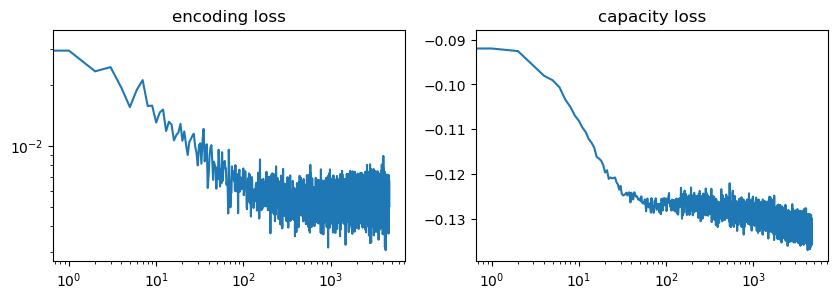

In [158]:
reload(pe)
options = pe.options
# SET OPTIONS #

options.trajectory_steps = 150000 #should cover a 1.5x1.5 metre box
options.real_or_riab = 'riab' #generated by ratinabox or loaded from a real trajectory?
options.maze_or_open_field = 'open_field' 
options.environment_scale = 1.5  # width and height (m) of square training environment
options.framerate = 1/60      # data rate for both position and place cell firingrate

#model options:
options.alpha = alpha #the balance between distance loss and capacity loss
options.sigma = sigma #adjust the separation of points in distance loss
options.n_first_hidden = 64
options.n_second_hidden = 128
options.n_grid_cells = 256
options.initialisation = 'kaiming' #'kaiming' or 'xavier' or 'identity'
options.model_type = 'FF' # TODO: implementing the RNN as well?

#training options
options.batch_size = 64
options.train_steps = 5000
options.learning_rate = 1e-3
options.optimizer = 'Adam' #'Adam' or 'AdamW' (the latter set to avoid implicit sparsity due to RELU activations)

  
model, losses, gridcell_metrics = pe.get_model_and_data(options)

In [161]:
reload(pe);pe.gridsearch_alpha_sigma(alpha,sigma)

Using device: cuda
Training model with alpha 0.99 and sigma 0.6
Loading existing model and data!
Done!


In [ ]:
#run the model through a train dataset
import pandas as pd

dataset = pe.PositionDataset(train_or_test='test')
dataset.positions
hidden_rates = []
with torch.no_grad():
    hidden_activations = model(dataset.positions)

pos_df = pd.DataFrame(dataset.positions.cpu(),
                      columns = ['centroid_position.x','centroid_position.y'])
hidden_activity_df = pd.DataFrame(hidden_activations.cpu().numpy(),
                                  columns = [f'firingrate.hidden_unit_{x}' for x in range(options.n_grid_cells)])

In [ ]:
from GridModels.code.measures import spatial
from GridModels.code.measures import grid_scorer; reload(grid_scorer)

dataset = pe.PositionDataset(train_or_test='test')
with torch.no_grad():
    hidden_activations = model(dataset.positions)
ratemaps, binx, biny = spatial.get_2D_ratemaps(hidden_activations.cpu().numpy(),
                                               dataset.positions.cpu().numpy())
gridcell_metrics = grid_scorer.get_grid_scores(ratemaps,binx,biny,
                                               return_metrics=True)

  1%|          | 3/256 [00:00<00:08, 29.09it/s]/ceph/behrens/peter_doohan/goalNav_mEC/experiment/code/GridModels/code/measures/grid_scorer.py:319: RuntimeWarning: When min_distance < 1, peak_local_max acts as finding image > max(threshold_abs, threshold_rel * max(image)).
  scale = (scale_in_sac_bins * rm_bins_per_sac_bin * meters_per_rm_bin)[
100%|██████████| 256/256 [00:09<00:00, 27.70it/s]


In [162]:
from Jobs.pettersen_parameters import gridsearch_alpha_sigma as gas; reload(gas)
gas.do_gridsearch()

Submitted batch job 1240011
Submitted job for alpha 0.1 sigma 0.5 to HPC. 
Submitted batch job 1240012
Submitted job for alpha 0.1 sigma 0.6 to HPC. 
Submitted batch job 1240013
Submitted job for alpha 0.1 sigma 0.7 to HPC. 
Submitted batch job 1240014
Submitted job for alpha 0.1 sigma 0.8 to HPC. 
Submitted batch job 1240015
Submitted job for alpha 0.1 sigma 0.9 to HPC. 
Submitted batch job 1240016
Submitted job for alpha 0.1 sigma 1.0 to HPC. 
Submitted batch job 1240017
Submitted job for alpha 0.1 sigma 1.1 to HPC. 
Submitted batch job 1240018
Submitted job for alpha 0.1 sigma 1.2 to HPC. 
Submitted batch job 1240019
Submitted job for alpha 0.1 sigma 1.3 to HPC. 
Submitted batch job 1240020
Submitted job for alpha 0.1 sigma 1.4 to HPC. 
Submitted batch job 1240021
Submitted job for alpha 0.2 sigma 0.5 to HPC. 
Submitted batch job 1240022
Submitted job for alpha 0.2 sigma 0.6 to HPC. 
Submitted batch job 1240023
Submitted job for alpha 0.2 sigma 0.7 to HPC. 
Submitted batch job 12400

In [133]:
from Jobs import get_SLURM_scripts as gss; 
reload(gss); reload(pe)
import os
alpha = 0.5
sigma = 0.5
script_path = gss.get_subject_SLURM_script_GPU(subject_ID=f'alpha_{alpha}.sigma_{sigma}',
                                                    jobs_directory=gas.JOBS_FOLDER,
                                                    job_label='pettersen',
                                                    conda_module_name = 'GridMaze',
                                                    script_import_name = 'GridModels.code.models.pettersen',
                                                    function_name= "gridsearch_alpha_sigma",
                                                    function_inputs=f"alpha = {alpha}, sigma = {sigma}",
                                                    RAM = "64GB",
                                                    n_cores = 8,
                                                    time_limit = "12:00:00")
os.system(f"chmod +x {script_path}")
os.system(f"sbatch {script_path}")
print(f'Submitted job for alpha {alpha} sigma {sigma} to HPC. ')

Using device: cuda
Submitted batch job 1239909
Submitted job for alpha 0.5 sigma 0.5 to HPC. 


In [ ]:
np.round(np.linspace)

In [150]:
!squeue -u cburns

             JOBID PARTITION     NAME     USER ST       TIME  NODES NODELIST(REASON)
           1239919      a100 petterse   cburns PD       0:00      1 (Resources)
           1239920      a100 petterse   cburns PD       0:00      1 (Priority)
           1239921      a100 petterse   cburns PD       0:00      1 (Priority)
           1239922      a100 petterse   cburns PD       0:00      1 (Priority)
           1239923      a100 petterse   cburns PD       0:00      1 (Priority)
           1239924      a100 petterse   cburns PD       0:00      1 (Priority)
           1239925      a100 petterse   cburns PD       0:00      1 (Priority)
           1239926      a100 petterse   cburns PD       0:00      1 (Priority)
           1239927      a100 petterse   cburns PD       0:00      1 (Priority)
           1239928      a100 petterse   cburns PD       0:00      1 (Priority)
           1239929      a100 petterse   cburns PD       0:00      1 (Priority)
           1239930      a100 petterse   cburn

Using device: cuda


100%|██████████| 2/2 [00:33<00:00, 16.75s/it]
/nfs/nhome/live/cburns/.conda/envs/GridMaze/lib/python3.10/site-packages/IPython/core/events.py:82: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  func(*args, **kwargs)


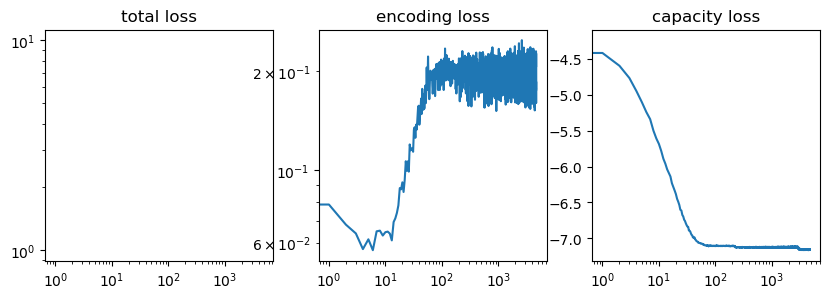

Timer unit: 1e-09 s

Total time: 33.748 s
File: /ceph/behrens/peter_doohan/goalNav_mEC/experiment/code/GridModels/code/models/pettersen.py
Function: train_model at line 175

Line #      Hits         Time  Per Hit   % Time  Line Contents
   175                                           def train_model(options, plot_losses = True):
   176                                                   
   177                                               # create dataset and dataloader
   178         1  213194026.0 2.13e+08      0.6      dataset = PositionDataset(n_steps=options.trajectory_steps)
   179         1     603040.0 603040.0      0.0      dataloader = DataLoader(dataset, batch_size=options.batch_size, shuffle=True)
   180                                               # instantiate model
   181         3    3911662.0  1.3e+06      0.0      model = PositionEncoder(alpha=options.alpha, sigma=options.sigma,
   182         1       1199.0   1199.0      0.0                              hidden_1_siz

In [58]:
reload(pe)
options.train_steps = 5000
%load_ext line_profiler
%lprun -f pe.train_model pe.train_model(options)

In [ ]:
hidden_activity_df = pe.generate_hidden_activity_df(model)

Using device: cuda
Trajectory not yet saved. Generating from scratch


100%|██████████| 150000/150000 [02:01<00:00, 1234.02it/s]


time centroid_position            velocity            \
                                    x         y         x         y   
0          0.016667          1.129922  0.050546 -0.076859  0.028427   
1          0.033333          1.128822  0.050999 -0.066037  0.027149   
2          0.050000          1.127676  0.051505 -0.068754  0.030413   
3          0.066667          1.126496  0.052047 -0.070796  0.032494   
4          0.083333          1.125352  0.052572 -0.068637  0.031476   
...             ...               ...       ...       ...       ...   
149995  2499.933333          1.448130  1.255382 -0.001520  0.092400   
149996  2499.950000          1.448114  1.256731 -0.000968  0.080951   
149997  2499.966667          1.448092  1.258029 -0.001310  0.077881   
149998  2499.983333          1.448034  1.259283 -0.003492  0.075238   
149999  2500.000000          1.447902  1.260537 -0.007911  0.075207   

       head_direction                      
                value         x         y  
0          171.148527 -0.988091  0.153874  
1          169.658429 -0.983755  0.179516  
2          168.165783 -0.978745  0.205081  
3          166.749528 -0.973377  0.229208  
4          165.490300 -0.968105  0.250544  
...               ...       ...       ...  
149995      98.657653 -0.150530  0.988605  
149996      97.773820 -0.135263  0.990810  
149997      97.018404 -0.122188  0.992507  
149998      96.534184 -0.113796  0.993504  
149999      96.475347 -0.112776  0.993620  

[150000 rows x 8 columns]

In [14]:
import pandas as pd
train_or_test = 'train'
filepath = pe.DATA_PATH/f'trajectories/riab.open_field.{train_or_test}.htsv'
df = pd.read_csv(filepath, sep='\t')
df.columns = pd.MultiIndex.from_tuples(
            [col.split('.') if '.' in col else (col,'') for col in df.columns])